# Quickstart: the OpenMRG CML release

Open the release, filter links, plot one event for one link, build a 5 min matrix for all train links in train events, and get the dry periods for a sub-link baseline. Times are UTC interval starts; definitions in `docs/methods.md`.

In [1]:
from pathlib import Path
import matplotlib.pyplot as plt
import pandas as pd
from cmlpipe.api import CMLData

root = Path.cwd() if (Path.cwd() / 'data').exists() else Path.cwd().parent   # run from the repo or examples/
d = CMLData.open(root / 'data/release/openmrg_v1')
d

CMLData(openmrg v1, 16 tables, 20 time series)

## 1. Filter links

In [2]:
links = d.links(length_km=(1, 3), frequency_band='>=25GHz', status='good', split='train', has_gauge_within_m=1000)
print(len(links), 'links')
links[['cml_id', 'length_m', 'frequency_ghz_sublink_1', 'nearest_gauge_id', 'nearest_gauge_distance_m']].head()

26 links


,cml_id,length_m,frequency_ghz_sublink_1,nearest_gauge_id,nearest_gauge_distance_m
0,10009,1482.814,37.2400,GbgA,620.476030
1,10010,1258.803,32.4450,Barl,37.690460
2,10012,1069.044,28.1785,Drakeg,873.971360
3,10015,1262.840,32.3610,GbgA,31.873010
4,10027,1049.585,37.2120,GbgA,338.162723


## 2. One event for one link: CML, radar along the path, the nearest gauge

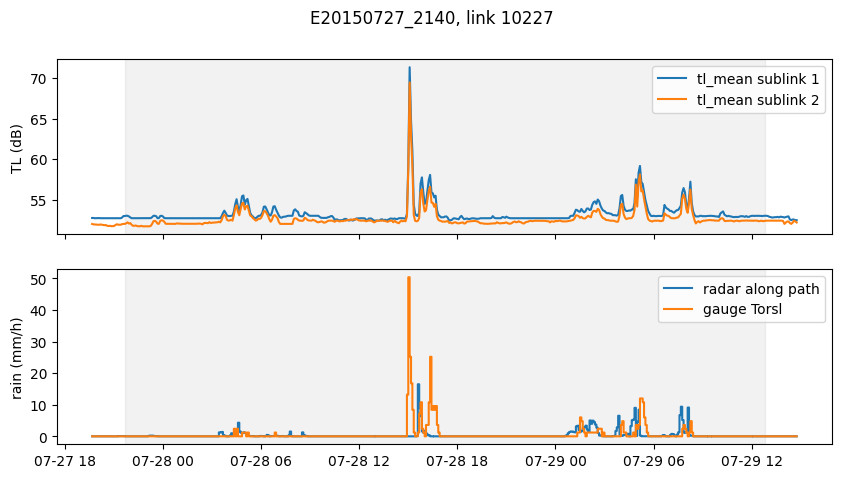

in_event  run_id              link_state  network_state
True      E20150727_2140_R02  0           1                80
          E20150727_2140_R04  1           1                75
          E20150727_2140_R02  -1          1                67
                              1           1                63
          E20150727_2140_R04  -1          1                59
Name: count, dtype: int64

In [3]:
ev = d.events(significant=True).set_index('event_id').loc['E20150727_2140']
w = d.event_window('E20150727_2140', cml_id=10227, pad='2h', res='5min')
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
a1.plot(w.index, w.tl_mean_s1, label='tl_mean sublink 1'); a1.plot(w.index, w.tl_mean_s2, label='tl_mean sublink 2')
a1.set_ylabel('TL (dB)'); a1.legend()
a2.step(w.index, w.radar_R_mean, where='post', label='radar along path')
a2.step(w.index, w.gauge_rate_mm_h, where='post', label=f"gauge {w.attrs['gauge']['gauge_id']}")
a2.set_ylabel('rain (mm/h)'); a2.legend()
for a in (a1, a2):
    a.axvspan(ev.start, ev.end, color='grey', alpha=0.1)
fig.suptitle('E20150727_2140, link 10227'); plt.show()
w[['in_event', 'run_id', 'link_state', 'network_state']].value_counts().head()

## 3. Bulk: 5 min tl_mean of all train links in all significant train events

In [4]:
train_links = d.links(split='train', status='good')
train_events = d.events(significant=True, split='train')
blocks = []
for e in train_events.itertuples():
    x = d.cml(train_links.cml_id, e.start, e.end, res='5min', variables=['tl_mean']).tl_mean.to_pandas()
    blocks.append(x.assign(event_id=e.event_id))
matrix = pd.concat(blocks)
print(matrix.shape, '(rows: time x event, columns: sub-links + event_id)')

(4766, 525) (rows: time x event, columns: sub-links + event_id)


## 4. Dry periods for a sub-link baseline

In [5]:
dry = d.dry_periods()
ds = d.cml('10227_1', '2015-07-01', '2015-08-01', res='1h', variables=['tl_median'])
tl = ds.tl_median.sel(sublink_id='10227_1').to_series()
in_dry = pd.Series(False, index=tl.index)
for p in dry.itertuples():
    in_dry |= (tl.index >= p.start) & (tl.index < p.end)
print(f'{in_dry.sum()} dry hours in July; dry median tl = {tl[in_dry].median():.2f} dB, '
      f'all-hours median = {tl.median():.2f} dB')

295 dry hours in July; dry median tl = 52.40 dB, all-hours median = 52.70 dB


## 5. What does a column mean?

In [6]:
d.describe('R_max')

,product,kind,dtype,unit,description
0,radar_along_links_5min,timeseries,float32,mm h-1,"largest cell rate under the path, max over the..."
1,radar_along_links_15min,timeseries,float32,mm h-1,"largest cell rate under the path, max over the..."
2,radar_along_links_1h,timeseries,float32,mm h-1,"largest cell rate under the path, max over the..."
